# TB Chest X-ray AI (TBX11K) — Google Colab

Knowledge-distillation pipeline for tuberculosis screening, inspired by a
teacher->student design, adapted to single-view chest X-rays:

1. **Preprocessing** — resize 384, geometric + photometric augmentation, normalise.
2. **Teacher** — DenseNet121 (strong, ImageNet transfer).
3. **Student** — MobileNetV3-Small (lightweight depthwise-separable CNN).
4. **Distillation (LogitKD)** — student learns from the teacher's soft logits
   plus the hard labels.
5. **Metrics** — Accuracy / Precision / Recall / F1 for both, side by side.
6. **Deployment** — INT8 quantization (PTQ + QAT) and a CPU benchmark.
7. **Detection** — TB-lesion bounding boxes (Faster R-CNN).

> Note: the reference design used two fundus views with dual-view fusion,
> CORAL ordinal heads and Complementarity Shift Distillation (CSD). TBX11K
> has a single X-ray per patient and nominal classes, so those pieces are
> not applicable; we keep the transferable ideas (lightweight student,
> logit distillation, INT8 CPU deployment).

> Screening aid, not a diagnosis. Every output carries a disclaimer.

**How to use:** Runtime -> GPU, then run top to bottom. Models are saved to
`/content/tb-pre-train/`.

## 📑 Daftar Isi & Alur Notebook (Overview)

Notebook ini dirancang untuk dijalankan secara berurutan (*top-to-bottom*) dan dibagi ke dalam **4 fase utama** agar mudah dipahami:

### 📂 Fase 1: Persiapan & Pemrosesan Data
*   **Sec 1 - 3:** Pengecekan GPU, instalasi dependensi (Kagglehub), dan setup kredensial API.
*   **Sec 4 - 5:** Pengunduhan dataset TBX11K (~3 GB) dan penerapan augmentasi geometris/fotometris pada gambar X-Ray.

### 🧠 Fase 2: Pelatihan Model (*Knowledge Distillation*)
*   **Sec 6:** Inisialisasi fungsi metrik evaluasi klasifikasi (Akurasi, Precision, Recall, F1-Score).
*   **Sec 7:** Pelatihan model **Teacher** (DenseNet121) — Model dengan parameter besar dan akurasi tinggi.
*   **Sec 8:** Pelatihan model **Student** (MobileNetV3) — Model sangat ringan yang belajar dari *Teacher* menggunakan metode *LogitKD*.
*   **Sec 9:** Komparasi awal performa metrik antara *Teacher* dan *Student*.

### 🚀 Fase 3: Optimasi *Deployment* & Deteksi Lesi TB
*   **Sec 10 - 11:** Kuantisasi model ke **INT8 (PTQ & QAT)**. Tujuannya memangkas ukuran model secara drastis agar sanggup berjalan super cepat di CPU (komputer klinik biasa) tanpa perlu GPU.
*   **Sec 12:** Pelatihan model Deteksi Objek (**Faster R-CNN**) untuk lokalisasi letak bercak/lesi TB (menghasilkan *bounding box* sebagai *explainable AI*).

### 📊 Fase 4: Pengujian, Unduhan, dan Analisis Akhir
*   **Sec 13 - 14:** Pengujian inferensi (*test* prediksi) pada 1 gambar sampel dan pencadangan model ke Google Drive.
*   **Sec 15 - 16:** Rangkuman kesimpulan eksekutif (*insight*) dan *script* untuk mengunduh semua model ke komputer lokal.
*   **Sec 17 - 18:** Visualisasi grafik efisiensi (Ukuran vs F1-Score) dan tabel *Ablation Study* yang membuktikan kehebatan model yang telah dikompresi.

## 1. Check the GPU

In [1]:
!nvidia-smi

Fri Oct 16 10:26:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install dependencies
Colab already has PyTorch + torchvision with CUDA. We just add kagglehub.

In [2]:
!pip -q install kagglehub tqdm
import torch, torchvision
print('torch', torch.__version__, '| cuda', torch.cuda.is_available(),
      '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

torch 2.11.0+cu130 | cuda True | Tesla T4


## 3. Kaggle credentials
Paste your Kaggle username + API key (from kaggle.com -> Settings -> Create New Token).
Running on Colab, these stay in the session only.

In [3]:
import os
os.environ['KAGGLE_USERNAME'] = '#####'   # <-- your username
os.environ['KAGGLE_KEY']      = '#####' # <-- your key (rotate after use)
print('Kaggle credentials set successfully.')

Kaggle user set: reynaldorey


## 4. Download TBX11K (~3 GB)
On Colab this is usually fast (minutes). Retries on connection drops.

In [4]:
import time, kagglehub
DATA_ROOT = None
for attempt in range(1, 11):
    try:
        print(f'[attempt {attempt}] downloading...')
        DATA_ROOT = kagglehub.dataset_download('usmanshams/tbx-11')
        break
    except Exception as e:
        print('failed:', e); time.sleep(10)
print('DATA_ROOT:', DATA_ROOT)

# Locate the TBX11K folder inside the download.
import os
ROOT = DATA_ROOT
for dp, dn, fn in os.walk(DATA_ROOT):
    if os.path.basename(dp) == 'imgs':
        ROOT = os.path.dirname(dp); break
print('TBX11K ROOT:', ROOT)
print('imgs subfolders:', os.listdir(os.path.join(ROOT, 'imgs')))

[attempt 1] downloading...


100%|██████████| 3.08G/3.08G [02:56<00:00, 18.7MB/s]

Extracting files...


DATA_ROOT: /root/.cache/kagglehub/datasets/usmanshams/tbx-11/versions/1
TBX11K ROOT: /root/.cache/kagglehub/datasets/usmanshams/tbx-11/versions/1/TBX11K
imgs subfolders: ['sick', 'health', 'tb', 'extra', 'test']


## 5. Data: classification (3 labelled folders) + preprocessing
Resize 384, geometric augmentation (flip/rotate/affine) and photometric
augmentation (brightness/contrast), then ImageNet normalisation.

In [52]:
import random
from pathlib import Path
from PIL import Image
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

# Memastikan reproduksibilitas secara global
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

IMG_EXTS = ('.png', '.jpg', '.jpeg')
LABELLED = {'health': 'Healthy', 'sick': 'Sick-non-TB', 'tb': 'TB'}
IMAGENET_MEAN = (0.485, 0.456, 0.406); IMAGENET_STD = (0.229, 0.224, 0.225)
IMG_SIZE = 384

def build_records(root):
    root = Path(root); classes = {}
    for folder, cname in LABELLED.items():
        d = Path(root) / 'imgs' / folder
        if d.is_dir():
            imgs = [p for p in d.iterdir() if p.suffix.lower() in IMG_EXTS]
            if imgs: classes.setdefault(cname, []).extend(imgs)
    names = sorted(classes); idx = {n:i for i,n in enumerate(names)}
    recs = [{'image': str(p), 'label': idx[c]} for c, ps in classes.items() for p in ps]
    return recs, names

def split(recs, val_fraction=0.15, seed=42):
    rng = random.Random(seed);
    by = {}
    for r in recs: by.setdefault(r['label'], []).append(r)
    tr, va = [], []
    for lab, items in by.items():
        items = items[:]; rng.shuffle(items)
        n = max(1, round(len(items)*val_fraction)); va += items[:n]; tr += items[n:]
    rng.shuffle(tr); rng.shuffle(va); return tr, va

class ClsDS(Dataset):
    def __init__(self, recs, size=IMG_SIZE, train=False):
        self.recs = recs
        if train:
            aug = [  # geometric (pairwise-style) + photometric (independent)
                T.RandomResizedCrop(size, scale=(0.85, 1.0)),
                T.RandomHorizontalFlip(0.5),
                T.RandomRotation(10),
                T.RandomAffine(0, translate=(0.05, 0.05)),
                T.ColorJitter(brightness=0.2, contrast=0.2),
            ]
        else:
            aug = [T.Resize((size, size))]
        self.tf = T.Compose(aug + [T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
    def __len__(self): return len(self.recs)
    def __getitem__(self, i):
        r = self.recs[i]
        return self.tf(Image.open(r['image']).convert('RGB')), r['label']

records, CLASS_NAMES = build_records(ROOT)
import collections
print('classes:', CLASS_NAMES)
print('counts :', collections.Counter(CLASS_NAMES[r['label']] for r in records))
print('total  :', len(records), '| image size', IMG_SIZE)

classes: ['Healthy', 'Sick-non-TB', 'TB']
counts : Counter({'Healthy': 3800, 'Sick-non-TB': 3800, 'TB': 800})
total  : 8400 | image size 384


## 6. Shared metrics (Accuracy / Precision / Recall / F1)
Macro-averaged over the 3 classes, plus per-class.

In [6]:
import numpy as np, torch
import torch.nn as nn, torchvision.models as tvm
from tqdm.auto import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH = 32
tr, va = split(records)
train_loader = DataLoader(ClsDS(tr, train=True),  batch_size=BATCH, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(ClsDS(va, train=False), batch_size=BATCH,
                          num_workers=2, pin_memory=True)

@torch.no_grad()
def compute_metrics(model, loader=None, dev=None):
    loader = loader or val_loader; dev = dev or device
    model.eval(); n = len(CLASS_NAMES); cm = np.zeros((n, n), int)
    for x, y in loader:
        x = x.to(dev)
        if dev.type == 'cuda':
            with torch.amp.autocast('cuda'):
                pred = model(x).argmax(1).cpu()
        else:
            pred = model(x).argmax(1).cpu()
        for t, p in zip(y, pred): cm[int(t), int(p)] += 1
    acc = cm.trace() / cm.sum(); P, R, F = [], [], []
    per = {}
    for c in range(n):
        tp = cm[c, c]; fp = cm[:, c].sum()-tp; fn = cm[c, :].sum()-tp
        p = tp/(tp+fp) if tp+fp else 0; r = tp/(tp+fn) if tp+fn else 0
        f = 2*p*r/(p+r) if p+r else 0
        per[CLASS_NAMES[c]] = dict(precision=round(p,4), recall=round(r,4),
                                   f1=round(f,4), support=int(cm[c,:].sum()))
        P.append(p); R.append(r); F.append(f)
    return dict(accuracy=round(float(acc),4), precision_macro=round(float(np.mean(P)),4),
                recall_macro=round(float(np.mean(R)),4), f1_macro=round(float(np.mean(F)),4),
                per_class=per, confusion_matrix=cm.tolist())

def print_metrics(name, m):
    print(f'\n=== {name} ===')
    print(f"  Accuracy  : {m['accuracy']:.4f}")
    print(f"  Precision : {m['precision_macro']:.4f} (macro)")
    print(f"  Recall    : {m['recall_macro']:.4f} (macro)")
    print(f"  F1        : {m['f1_macro']:.4f} (macro)")
    for cls, v in m['per_class'].items():
        print(f"    {cls:12s} P={v['precision']:.3f} R={v['recall']:.3f} "
              f"F1={v['f1']:.3f} (n={v['support']})")

def n_params(m): return sum(p.numel() for p in m.parameters())

counts = torch.zeros(len(CLASS_NAMES))
for r in tr: counts[r['label']] += 1
CLASS_W = (counts.sum() / (len(CLASS_NAMES) * counts.clamp(min=1))).to(device)
print('class weights:', [round(float(w),3) for w in CLASS_W])

class weights: [0.737, 0.737, 3.5]


## 7. Train the TEACHER (DenseNet121)
Strong backbone, ImageNet transfer learning. Saved as `tb_teacher.pt`.

In [7]:
import os
os.makedirs('/content/tb-pre-train', exist_ok=True)
T_EPOCHS = 15; LR = 3e-4

teacher = tvm.densenet121(weights=tvm.DenseNet121_Weights.IMAGENET1K_V1)
teacher.classifier = nn.Linear(teacher.classifier.in_features, len(CLASS_NAMES))
teacher = teacher.to(device)
opt = torch.optim.AdamW(teacher.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T_EPOCHS)
scaler = torch.amp.GradScaler('cuda')
loss_fn = nn.CrossEntropyLoss(weight=CLASS_W)

best = -1; teacher_metrics = None
for ep in range(1, T_EPOCHS+1):
    teacher.train(); pbar = tqdm(train_loader, desc=f'teacher {ep}/{T_EPOCHS}')
    for x, y in pbar:
        x, y = x.to(device), y.to(device)
        opt.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            loss = loss_fn(teacher(x), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        pbar.set_postfix(loss=f'{loss.item():.4f}')
    sched.step()
    m = compute_metrics(teacher)
    print(f"teacher {ep}/{T_EPOCHS} | acc {m['accuracy']:.4f} F1 {m['f1_macro']:.4f}"
          + ('  <-- best' if m['f1_macro'] > best else ''))
    if m['f1_macro'] > best:
        best = m['f1_macro']; teacher_metrics = m
        torch.save({'state_dict': teacher.state_dict(),
                    'meta': {'role':'teacher','backbone':'densenet121',
                             'class_names':CLASS_NAMES,'image_size':IMG_SIZE,'metrics':m}},
                   '/content/tb-pre-train/tb_teacher.pt')
teacher.load_state_dict(torch.load('/content/tb-pre-train/tb_teacher.pt',
                                   map_location=device, weights_only=False)['state_dict'])
teacher.eval()
print_metrics('TEACHER (DenseNet121)', teacher_metrics)
print('teacher params:', f'{n_params(teacher):,}')


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 221MB/s]


teacher 1/15:   0%|          | 0/224 [00:00<?, ?it/s]

teacher 1/15 | acc 0.7405 F1 0.6737  <-- best


teacher 2/15:   0%|          | 0/224 [00:00<?, ?it/s]

...

teacher 14/15 | acc 0.9960 F1 0.9926


teacher 15/15:   0%|          | 0/224 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Exception ignored in:     assert self._parent_pid == os.getpid(), 'can only test a child process'
<function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>AssertionError
: Traceback (most recent call last):
can only test a child process  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    self._shutdown_workers()Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/d

teacher 15/15 | acc 0.9960 F1 0.9926


UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray.scalar was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])` or the `torch.serialization.safe_globals([numpy._core.multiarray.scalar])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn 

### Analisis Latensi CPU (Teacher)
Mari kita ukur seberapa berat model Teacher (DenseNet121) jika dijalankan murni menggunakan CPU komputer biasa.

In [26]:
import time
import torch

print("Mengukur latensi CPU untuk model Teacher (DenseNet121)...")

# Pindahkan model ke CPU untuk pengujian
teacher_cpu = teacher.to('cpu')
teacher_cpu.eval()

# Buat dummy input dengan ukuran gambar yang sesuai
dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to('cpu')

# Warmup (Pemanasan agar hasil pengukuran lebih akurat)
with torch.no_grad():
    for _ in range(3):
        teacher_cpu(dummy_input)

# Pengukuran latensi sesungguhnya
n_iters = 30
t0 = time.time()
with torch.no_grad():
    for _ in range(n_iters):
        teacher_cpu(dummy_input)

teacher_ms_per_img = (time.time() - t0) / n_iters * 1000
print(f"Latensi CPU Teacher (DenseNet121): {teacher_ms_per_img:.1f} ms/gambar")

# Kembalikan model ke device awal (GPU) agar tidak menyebabkan error di proses berikutnya
teacher = teacher.to(device)


Mengukur latensi CPU untuk model Teacher (DenseNet121)...
Latensi CPU Teacher (DenseNet121): 112.9 ms/gambar


## 8. Train the STUDENT (MobileNetV3-Small) via LogitKD
Lightweight depthwise-separable CNN. **LogitKD** loss:
`L = alpha * KL(student_soft || teacher_soft) * T^2 + (1-alpha) * CE(student, labels)`

In [9]:
ALPHA = 0.7     # weight on distillation vs hard-label loss
TEMP = 4.0      # softmax temperature
S_EPOCHS = 20

student = tvm.mobilenet_v3_small(weights=tvm.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
in_feat = student.classifier[-1].in_features
student.classifier[-1] = nn.Linear(in_feat, len(CLASS_NAMES))
student = student.to(device)
opt = torch.optim.AdamW(student.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=S_EPOCHS)
scaler = torch.amp.GradScaler('cuda')
ce = nn.CrossEntropyLoss(weight=CLASS_W)
kl = nn.KLDivLoss(reduction='batchmean')

def logit_kd(s_logits, t_logits, y):
    soft = kl(torch.log_softmax(s_logits / TEMP, 1),
              torch.softmax(t_logits / TEMP, 1)) * (TEMP ** 2)
    hard = ce(s_logits, y)
    return ALPHA * soft + (1 - ALPHA) * hard

best = -1; student_metrics = None
for ep in range(1, S_EPOCHS+1):
    student.train(); pbar = tqdm(train_loader, desc=f'student {ep}/{S_EPOCHS}')
    for x, y in pbar:
        x, y = x.to(device), y.to(device)
        with torch.no_grad(), torch.amp.autocast('cuda'):
            t_logits = teacher(x)
        opt.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            s_logits = student(x)
            loss = logit_kd(s_logits, t_logits.float(), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        pbar.set_postfix(loss=f'{loss.item():.4f}')
    sched.step()
    m = compute_metrics(student)
    print(f"student {ep}/{S_EPOCHS} | acc {m['accuracy']:.4f} F1 {m['f1_macro']:.4f}"
          + ('  <-- best' if m['f1_macro'] > best else ''))
    if m['f1_macro'] > best:
        best = m['f1_macro']; student_metrics = m
        torch.save({'state_dict': student.state_dict(),
                    'meta': {'role':'student','backbone':'mobilenet_v3_small',
                             'class_names':CLASS_NAMES,'image_size':IMG_SIZE,
                             'alpha':ALPHA,'temperature':TEMP,'metrics':m}},
                   '/content/tb-pre-train/tb_student.pt')
student.load_state_dict(torch.load('/content/tb-pre-train/tb_student.pt',
                                   map_location=device, weights_only=False)['state_dict'])
student.eval()
print_metrics('STUDENT (MobileNetV3-Small, LogitKD)', student_metrics)
print('student params:', f'{n_params(student):,}')


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 179MB/s]


student 1/20:   0%|          | 0/224 [00:00<?, ?it/s]

student 1/20 | acc 0.9492 F1 0.8851  <-- best


student 2/20:   0%|          | 0/224 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

student 19/20 | acc 0.9976 F1 0.9960  <-- best


student 20/20:   0%|          | 0/224 [00:00<?, ?it/s]

student 20/20 | acc 0.9952 F1 0.9910


UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray.scalar was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])` or the `torch.serialization.safe_globals([numpy._core.multiarray.scalar])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn 

## 9. Teacher vs Student — metrics comparison

In [10]:
def row(name, m, params):
    return (f"{name:30s} {m['accuracy']:<9.4f} {m['precision_macro']:<11.4f} "
            f"{m['recall_macro']:<9.4f} {m['f1_macro']:<9.4f} {params:>12,}")
print(f"{'Model':30s} {'Accuracy':9s} {'Precision':11s} {'Recall':9s} {'F1':9s} {'Params':>12s}")
print('-'*84)
print(row('Teacher (DenseNet121)', teacher_metrics, n_params(teacher)))
print(row('Student (MobileNetV3, KD)', student_metrics, n_params(student)))
print('-'*84)
print(f'Student is {n_params(teacher)/max(n_params(student),1):.1f}x smaller than the teacher.')
import json
json.dump({'teacher':teacher_metrics,'student':student_metrics,
           'teacher_params':n_params(teacher),'student_params':n_params(student)},
          open('/content/tb-pre-train/metrics_comparison.json','w'), indent=2)
print('\nSaved -> /content/tb-pre-train/metrics_comparison.json')

Model                          Accuracy  Precision   Recall    F1              Params
------------------------------------------------------------------------------------
Teacher (DenseNet121)          0.9960    0.9948      0.9905    0.9926       6,956,931
Student (MobileNetV3, KD)      0.9976    0.9982      0.9939    0.9960       1,520,931
------------------------------------------------------------------------------------
Student is 4.6x smaller than the teacher.

Saved -> /content/tb-pre-train/metrics_comparison.json


## 9b. Train Student WITHOUT KD (Ablation Baseline)
Melatih MobileNetV3-Small murni menggunakan label klasifikasi (tanpa panduan probabilitas dari Teacher) untuk membuktikan apakah KD benar-benar memberikan dampak positif.

In [43]:
S_NO_KD_EPOCHS = 20

student_no_kd = tvm.mobilenet_v3_small(weights=tvm.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
in_feat = student_no_kd.classifier[-1].in_features
student_no_kd.classifier[-1] = nn.Linear(in_feat, len(CLASS_NAMES))
student_no_kd = student_no_kd.to(device)

opt_no_kd = torch.optim.AdamW(student_no_kd.parameters(), lr=3e-4, weight_decay=1e-4)
sched_no_kd = torch.optim.lr_scheduler.CosineAnnealingLR(opt_no_kd, T_max=S_NO_KD_EPOCHS)
scaler_no_kd = torch.amp.GradScaler('cuda')
ce_no_kd = nn.CrossEntropyLoss(weight=CLASS_W)

best_no_kd = -1
student_no_kd_metrics = None

for ep in range(1, S_NO_KD_EPOCHS+1):
    student_no_kd.train()
    pbar = tqdm(train_loader, desc=f'student_no_kd {ep}/{S_NO_KD_EPOCHS}')
    for x, y in pbar:
        x, y = x.to(device), y.to(device)
        opt_no_kd.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            logits = student_no_kd(x)
            loss = ce_no_kd(logits, y)
        scaler_no_kd.scale(loss).backward()
        scaler_no_kd.step(opt_no_kd)
        scaler_no_kd.update()
        pbar.set_postfix(loss=f'{loss.item():.4f}')
    sched_no_kd.step()

    m = compute_metrics(student_no_kd)
    print(f"student_no_kd {ep}/{S_NO_KD_EPOCHS} | acc {m['accuracy']:.4f} F1 {m['f1_macro']:.4f}"
          + ('  <-- best' if m['f1_macro'] > best_no_kd else ''))

    if m['f1_macro'] > best_no_kd:
        best_no_kd = m['f1_macro']
        student_no_kd_metrics = m
        torch.save({'state_dict': student_no_kd.state_dict(),
                    'meta': {'role':'student_no_kd','backbone':'mobilenet_v3_small',
                             'class_names':CLASS_NAMES,'image_size':IMG_SIZE,'metrics':m}},
                   '/content/tb-pre-train/tb_student_no_kd.pt')

student_no_kd.load_state_dict(torch.load('/content/tb-pre-train/tb_student_no_kd.pt', map_location=device, weights_only=False)['state_dict'])
student_no_kd.eval()
print_metrics('STUDENT (MobileNetV3-Small, NO KD)', student_no_kd_metrics)

student_no_kd 1/20:   0%|          | 0/224 [00:00<?, ?it/s]

student_no_kd 1/20 | acc 0.9151 F1 0.8830  <-- best


student_no_kd 2/20:   0%|          | 0/224 [00:00<?, ?it/s]

student_no_kd 2/20 | acc 0.5849 F1 0.5490


student_no_kd 3/20:   0%|          | 0/224 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

student_no_kd 19/20 | acc 0.9960 F1 0.9915


student_no_kd 20/20:   0%|          | 0/224 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

student_no_kd 20/20 | acc 0.9960 F1 0.9915

=== STUDENT (MobileNetV3-Small, NO KD) ===
  Accuracy  : 0.9952
  Precision : 0.9943 (macro)
  Recall    : 0.9899 (macro)
  F1        : 0.9921 (macro)
    Healthy      P=0.995 R=1.000 F1=0.997 (n=570)
    Sick-non-TB  P=0.997 R=0.995 F1=0.996 (n=570)
    TB           P=0.992 R=0.975 F1=0.983 (n=120)


## 10. Deployment: INT8 quantization (PTQ / QAT) + CPU benchmark
Shrink the student for CPU deployment. **PTQ** quantizes the trained model
post-hoc (fast); **QAT** fine-tunes with fake-quant for better accuracy.
Both target INT8 and run on CPU.

In [12]:
import copy, time, os
import torch, torch.nn as nn, torchvision.models as tvm

cpu = torch.device('cpu')

def build_student():
    m = tvm.mobilenet_v3_small(weights=None)
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, len(CLASS_NAMES))
    return m

# fresh FP32 student (best weights) on CPU for quantization
fp32 = build_student()
fp32.load_state_dict(torch.load('/content/tb-pre-train/tb_student.pt',
                                map_location='cpu', weights_only=False)['state_dict'])
fp32.eval().to(cpu)

def model_size_mb(m):
    torch.save(m.state_dict(), '/tmp/_m.pt')
    return os.path.getsize('/tmp/_m.pt') / 1e6

@torch.no_grad()
def cpu_latency(m, n=30):
    m.eval(); x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    for _ in range(3): m(x)            # warmup
    t0 = time.time()
    for _ in range(n): m(x)
    return (time.time()-t0)/n*1000      # ms/image

# ---- PTQ (dynamic INT8: quantizes Linear layers, simple & robust) ----
ptq = torch.ao.quantization.quantize_dynamic(
    copy.deepcopy(fp32), {nn.Linear}, dtype=torch.qint8)
ptq.eval()

# ---- metrics on CPU for FP32 vs PTQ ----
cpu_val = DataLoader(ClsDS(va, train=False), batch_size=16, num_workers=2)
m_fp32 = compute_metrics(fp32, loader=cpu_val, dev=cpu)
m_ptq  = compute_metrics(ptq,  loader=cpu_val, dev=cpu)

print(f"{'Variant':16s} {'F1':8s} {'Acc':8s} {'Size(MB)':10s} {'CPU ms/img':10s}")
print('-'*54)
print(f"{'FP32':16s} {m_fp32['f1_macro']:<8.4f} {m_fp32['accuracy']:<8.4f} "
      f"{model_size_mb(fp32):<10.2f} {cpu_latency(fp32):<10.1f}")
print(f"{'PTQ INT8':16s} {m_ptq['f1_macro']:<8.4f} {m_ptq['accuracy']:<8.4f} "
      f"{model_size_mb(ptq):<10.2f} {cpu_latency(ptq):<10.1f}")

torch.save(ptq.state_dict(), '/content/tb-pre-train/tb_student_ptq_int8.pt')
print('\nSaved PTQ INT8 -> /content/tb-pre-train/tb_student_ptq_int8.pt')

/tmp/ipykernel_1225/3542816187.py:30: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  ptq = torch.ao.quantization.quantize_dynamic(


Variant          F1       Acc      Size(MB)   CPU ms/img
------------------------------------------------------
FP32             0.9954   0.9968   6.20       13.8      
PTQ INT8         0.9954   0.9968   4.43       13.7      

Saved PTQ INT8 -> /content/tb-pre-train/tb_student_ptq_int8.pt


## 11. (Optional) QAT INT8 — fine-tune with fake-quant
A few epochs of quantization-aware training usually recovers accuracy lost
to PTQ. Uses the FBGEMM backend (x86 CPU).

In [14]:
import copy
# Pick an available INT8 backend (Colab x86 usually has fbgemm; fall back
# to qnnpack/onednn elsewhere). QAT is skipped gracefully if none support it.
_engines = list(torch.backends.quantized.supported_engines)
_pref = [e for e in ('fbgemm', 'onednn', 'qnnpack') if e in _engines]
print('quantization engines available:', _engines, '-> using', _pref[:1])

if not _pref:
    print('No INT8 QAT backend available here; skipping QAT (PTQ above still works).')
else:
    BACKEND = _pref[0]
    torch.backends.quantized.engine = BACKEND
    qat = build_student()
    qat.load_state_dict(torch.load('/content/tb-pre-train/tb_student.pt',
                                   map_location='cpu', weights_only=False)['state_dict'])
    qat.train()
    qat.qconfig = torch.ao.quantization.get_default_qat_qconfig(BACKEND)
    torch.ao.quantization.prepare_qat(qat, inplace=True)
    qat = qat.to(device)

    QAT_EPOCHS = 3
    optq = torch.optim.AdamW(qat.parameters(), lr=5e-5)
    ce = nn.CrossEntropyLoss(weight=CLASS_W)
    for ep in range(1, QAT_EPOCHS+1):
        qat.train(); pbar = tqdm(train_loader, desc=f'QAT {ep}/{QAT_EPOCHS}')
        for x, y in pbar:
            x, y = x.to(device), y.to(device)
            optq.zero_grad(set_to_none=True)
            loss = ce(qat(x), y)   # fake-quant forward in fp32 (no AMP)
            loss.backward(); optq.step()
            pbar.set_postfix(loss=f'{loss.item():.4f}')

    qat.eval().to(cpu)
    try:
        qat_int8 = torch.ao.quantization.convert(qat, inplace=False)
        m_qat = compute_metrics(qat_int8, loader=cpu_val, dev=cpu)
        print(f"QAT INT8  | F1 {m_qat['f1_macro']:.4f} acc {m_qat['accuracy']:.4f} "
              f"size {model_size_mb(qat_int8):.2f} MB  {cpu_latency(qat_int8):.1f} ms/img")
        torch.save(qat_int8.state_dict(), '/content/tb-pre-train/tb_student_qat_int8.pt')
        print('Saved QAT INT8 -> /content/tb-pre-train/tb_student_qat_int8.pt')
    except (RuntimeError, NotImplementedError) as e:
        print('QAT INT8 convert not supported by this backend:', str(e)[:120])
        print('Use the PTQ INT8 model from the previous cell for CPU deployment.')

quantization engines available: ['qnnpack', 'onednn', 'x86', 'fbgemm'] -> using ['fbgemm']


/tmp/ipykernel_1225/1553910635.py:18: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.ao.quantization.prepare_qat(qat, inplace=True)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:534: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release o

QAT 1/3:   0%|          | 0/224 [00:00<?, ?it/s]

QAT 2/3:   0%|          | 0/224 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

QAT 3/3:   0%|          | 0/224 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

QAT INT8 convert not supported by this backend: Could not run 'quantized::conv2d.new' with arguments from the 'CPU' backend. This could be because the operator doesn't 
Use the PTQ INT8 model from the previous cell for CPU deployment.


## 12. Train the TB-lesion detector (Faster R-CNN)
Uses the COCO-style box annotations shipped with TBX11K.

In [15]:
import json, glob
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
import torchvision.transforms.functional as F

ann = None
for p in glob.glob(os.path.join(ROOT, '**', 'all_train.json'), recursive=True):
    ann = p; break
print('annotation:', ann)

def index_images(root):
    idx = {}
    for dp, _, fn in os.walk(root):
        for f in fn:
            if f.lower().endswith(IMG_EXTS): idx.setdefault(f, os.path.join(dp, f))
    return idx

def load_coco(ann, root):
    data = json.load(open(ann)); img_idx = index_images(root)
    id2f = {im['id']: im.get('file_name') for im in data['images']}
    boxes = {}
    for a in data['annotations']:
        x, y, w, h = a['bbox']; boxes.setdefault(a['image_id'], []).append([x, y, x+w, y+h])
    recs = []
    for iid, bx in boxes.items():
        fn = id2f.get(iid)
        if not fn: continue
        path = img_idx.get(os.path.basename(fn))
        if path: recs.append({'image': path, 'boxes': bx})
    return recs

det_recs = load_coco(ann, ROOT)
print('boxed images:', len(det_recs))

DSIZE = 512
class DetDS(Dataset):
    def __init__(self, recs, train=False): self.recs = recs; self.train = train
    def __len__(self): return len(self.recs)
    def __getitem__(self, i):
        r = self.recs[i]; img = Image.open(r['image']).convert('RGB'); w0, h0 = img.size
        img = img.resize((DSIZE, DSIZE)); sx, sy = DSIZE/w0, DSIZE/h0
        b = torch.tensor([[x1*sx, y1*sy, x2*sx, y2*sy] for x1,y1,x2,y2 in r['boxes']], dtype=torch.float32)
        tgt = {'boxes': b, 'labels': torch.ones(len(b), dtype=torch.int64), 'image_id': torch.tensor([i])}
        return F.to_tensor(img), tgt

random.Random(42).shuffle(det_recs)
nv = max(1, round(len(det_recs)*0.15)); dval, dtrain = det_recs[:nv], det_recs[nv:]
collate = lambda b: tuple(zip(*b))
dtl = DataLoader(DetDS(dtrain, True), batch_size=4, shuffle=True, num_workers=2, collate_fn=collate)
dvl = DataLoader(DetDS(dval), batch_size=4, num_workers=2, collate_fn=collate)

det = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights='DEFAULT')
det.roi_heads.box_predictor = FastRCNNPredictor(det.roi_heads.box_predictor.cls_score.in_features, 2)
det = det.to(device)
dopt = torch.optim.AdamW([p for p in det.parameters() if p.requires_grad], lr=5e-4, weight_decay=1e-4)
dsc = torch.amp.GradScaler('cuda')

DET_EPOCHS = 15; dbest = 1e9
for ep in range(1, DET_EPOCHS+1):
    det.train(); pbar = tqdm(dtl, desc=f'det epoch {ep}/{DET_EPOCHS}')
    for imgs, tgts in pbar:
        imgs = [im.to(device) for im in imgs]; tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
        dopt.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            loss = sum(det(imgs, tgts).values())
        dsc.scale(loss).backward(); dsc.step(dopt); dsc.update()
        pbar.set_postfix(loss=f'{loss.item():.4f}')
    # val loss
    det.train(); vl = []
    with torch.no_grad():
        for imgs, tgts in dvl:
            imgs = [im.to(device) for im in imgs]; tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
            vl.append(float(sum(det(imgs, tgts).values()).item()))
    vloss = sum(vl)/len(vl)
    print(f'det epoch {ep}/{DET_EPOCHS} | val_loss {vloss:.4f}' + ('  <-- best' if vloss < dbest else ''))
    if vloss < dbest:
        dbest = vloss
        torch.save({'state_dict': det.state_dict(),
                    'meta': {'image_size': DSIZE, 'num_classes': 2, 'score_threshold': 0.5}},
                   '/content/tb-pre-train/tb_detector.pt')
print('best det val_loss:', dbest, '-> /content/tb-pre-train/tb_detector.pt')

annotation: /root/.cache/kagglehub/datasets/usmanshams/tbx-11/versions/1/TBX11K/annotations/json/all_train.json
boxed images: 599
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 252MB/s]


det epoch 1/15:   0%|          | 0/128 [00:00<?, ?it/s]

det epoch 1/15 | val_loss 0.3404  <-- best


det epoch 2/15:   0%|          | 0/128 [00:00<?, ?it/s]

...

det epoch 14/15:   0%|          | 0/128 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    Exception ignored in: if w.is_alive():
<function _MultiProcessingDataLoaderIter.__del__ at 0x795fd0d9e160>  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

    Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError    : self._shutdown_workers()can only test a child process

Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
<function _Multi

det epoch 14/15 | val_loss 0.2468  <-- best


det epoch 15/15:   0%|          | 0/128 [00:00<?, ?it/s]

det epoch 15/15 | val_loss 0.2915
best det val_loss: 0.2467549125785413 -> /content/tb-pre-train/tb_detector.pt


## 13. (Optional) Save models to Google Drive

In [16]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/tb-pre-train
!cp /content/tb-pre-train/*.pt /content/drive/MyDrive/tb-pre-train/
!cp /content/tb-pre-train/*.json /content/drive/MyDrive/tb-pre-train/
print('Saved to Google Drive -> MyDrive/tb-pre-train/')

Mounted at /content/drive
Saved to Google Drive -> MyDrive/tb-pre-train/


## 14. Quick inference test (student model)

In [18]:
import glob
ckpt = torch.load('/content/tb-pre-train/tb_student.pt', map_location=device, weights_only=False)
names = ckpt['meta']['class_names']; size = ckpt['meta']['image_size']
m = tvm.mobilenet_v3_small(weights=None)
m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, len(names))
m.load_state_dict(ckpt['state_dict']); m = m.to(device).eval()
tf = T.Compose([T.Resize((size, size)), T.ToTensor(),
                T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
sample = glob.glob(os.path.join(ROOT, 'imgs', 'tb', '*.png'))[0]
with torch.no_grad():
    probs = torch.softmax(m(tf(Image.open(sample).convert('RGB')).unsqueeze(0).to(device)), 1)[0].cpu()
print('image:', os.path.basename(sample))
print({names[i]: round(float(probs[i]), 4) for i in range(len(names))})
print('DISCLAIMER: AI screening aid, not a medical diagnosis. Consult a clinician.')

image: tb1049.png
{'Healthy': 0.0, 'Sick-non-TB': 0.0, 'TB': 1.0}
DISCLAIMER: AI screening aid, not a medical diagnosis. Consult a clinician.


## 15. Recap & Insight Keseluruhan Pipeline

Berikut adalah ringkasan objektif dari pipeline *Knowledge Distillation* untuk skrining Tuberculosis (TB) yang telah dibangun:

### 1. Perbandingan Performa Model (Klasifikasi)
Dari hasil evaluasi pada *validation set*, berikut perbandingan metrik aktual antara model *Teacher*, *Student*, dan hasil kuantisasi:
*   **Teacher (DenseNet121):** Akurasi ~99.60% | Precision ~99.48% | Recall ~99.05% | F1-Score ~99.26% *(diukur di GPU)*
*   **Student FP32 (MobileNetV3-Small) di CPU:** Akurasi ~99.68% | F1-Score ~99.54% *(dievaluasi secara adil di CPU)*
*   **Student PTQ INT8 di CPU:** Akurasi ~99.68% | F1-Score ~99.54% *(dievaluasi secara adil di CPU)*

### 2. Insight Utama & Evaluasi Kritis
*   **Penyusutan Ukuran Model**: Model *Student* memiliki parameter ~4.6x lebih kecil (~1.5M parameter) dibandingkan *Teacher* (~6.9M parameter), sehingga sangat efisien untuk dijalankan pada perangkat dengan sumber daya terbatas.
*   **Efektivitas Distilasi (LogitKD)**: Secara nominal, model *Student* dengan KD mencapai nilai metrik yang sangat bersaing dengan *Teacher*. Namun, perlu dicatat bahwa perbedaan performa mutlak di antara variasi model ini sangatlah tipis, sehingga memerlukan pengujian lebih lanjut untuk memastikan signifikansi statistiknya.
*   **Sumber Akselerasi Riil**: Lompatan kecepatan eksekusi yang masif (dari ~113 ms menjadi ~15 ms per gambar) murni didorong oleh pergantian arsitektur ke MobileNetV3 yang jauh lebih ringan, bukan karena kuantisasi.
*   **Dampak Kuantisasi INT8:** Melalui *Post-Training Quantization* (PTQ), ukuran penyimpanan model berhasil dipangkas sekitar **~28%** (dari 6.20 MB menjadi 4.43 MB). Namun, pada pengujian CPU tunggal ini, kuantisasi INT8 tidak memberikan degradasi performa (F1-score tetap bertahan sempurna di 99.54% sama seperti versi FP32-nya) dan juga tidak memberikan tambahan kecepatan inferensi (latensi stabil di ~15 ms), membuktikan bahwa manfaat utama PTQ di sini murni pada aspek minimalisasi ruang penyimpanan.

## 15b. Analisis Kritis Studi Ablasi (KD vs Tanpa KD)

*(Seksi ini menyajikan evaluasi kritis terhadap hasil eksperimen tunggal)*

*   **Tanpa KD (Ablation Baseline):** Model MobileNetV3-Small yang dilatih murni menggunakan label klasifikasi menghasilkan F1-Score sebesar **99.21%**.
*   **Dengan KD (Metode LogitKD):** Model yang dipandu oleh logit DenseNet121 mencatatkan F1-Score sebesar **99.60%** *(diukur pada GPU)*.
*   **Catatan Metodologi yang Penting (Konteks Realistis):**
    *   Meskipun terdapat kenaikan nominal F1-Score sebesar **0.39%**, perbedaan riil pada deteksi kelas TB hanya sebesar **1 gambar saja** (model KD mendeteksi **118 dari 120** gambar TB aktif, sedangkan model tanpa KD mendeteksi **117 dari 120** gambar).
    *   Pada keseluruhan data validasi (1.260 gambar), model dengan KD melakukan salah prediksi pada **3 gambar**, sementara model tanpa KD salah pada **6 gambar**.
    *   Karena evaluasi ini didasarkan pada **satu kali proses training (single run)**, selisih sekecil ini sangat mungkin dipengaruhi oleh faktor acak seperti *initialization seed* atau fluktuasi stokastik saat optimasi. Untuk menarik kesimpulan ilmiah yang kuat bahwa KD mendatangkan perbaikan performa yang signifikan, diperlukan eksperimen berulang (*cross-validation* multi-fold atau *multiple seeds*) guna mengukur rata-rata dan standar deviasi performa secara akurat.

## 16. Unduh Model ke Komputer Lokal
Jalankan cell di bawah ini untuk mengunduh semua versi model yang telah dilatih (Teacher, Student, INT8) dan file metrik ke komputer lokal Anda.

In [20]:
from google.colab import files
import os

# Daftar file model dan metrik yang akan diunduh
files_to_download = [
    '/content/tb-pre-train/tb_teacher.pt',            # Model Teacher (DenseNet121)
    '/content/tb-pre-train/tb_student.pt',            # Model Student FP32 (MobileNetV3)
    '/content/tb-pre-train/tb_student_ptq_int8.pt',   # Model Student PTQ INT8
    '/content/tb-pre-train/tb_student_qat_int8.pt',   # Model Student QAT INT8 (Jika ada)
    '/content/tb-pre-train/tb_detector.pt',           # Model Faster R-CNN (Detector)
    '/content/tb-pre-train/metrics_comparison.json'   # File metrik komparasi
]

print("Memeriksa file dan memulai proses unduh...")
for file_path in files_to_download:
    if os.path.exists(file_path):
        print(f"Mengunduh: {os.path.basename(file_path)}")
        files.download(file_path)
    else:
        print(f"[Lewati] File tidak ditemukan: {os.path.basename(file_path)}")

Memeriksa file dan memulai proses unduh...
Mengunduh: tb_teacher.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mengunduh: tb_student.pt


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mengunduh: metrics_comparison.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Visualisasi Perbandingan Model (Insight Efisiensi)
Bagian ini menggunakan `matplotlib` untuk memvisualisasikan *trade-off* antara akurasi dan ukuran model. Kita akan melihat mengapa model **Student INT8** sangat optimal untuk *deployment*.

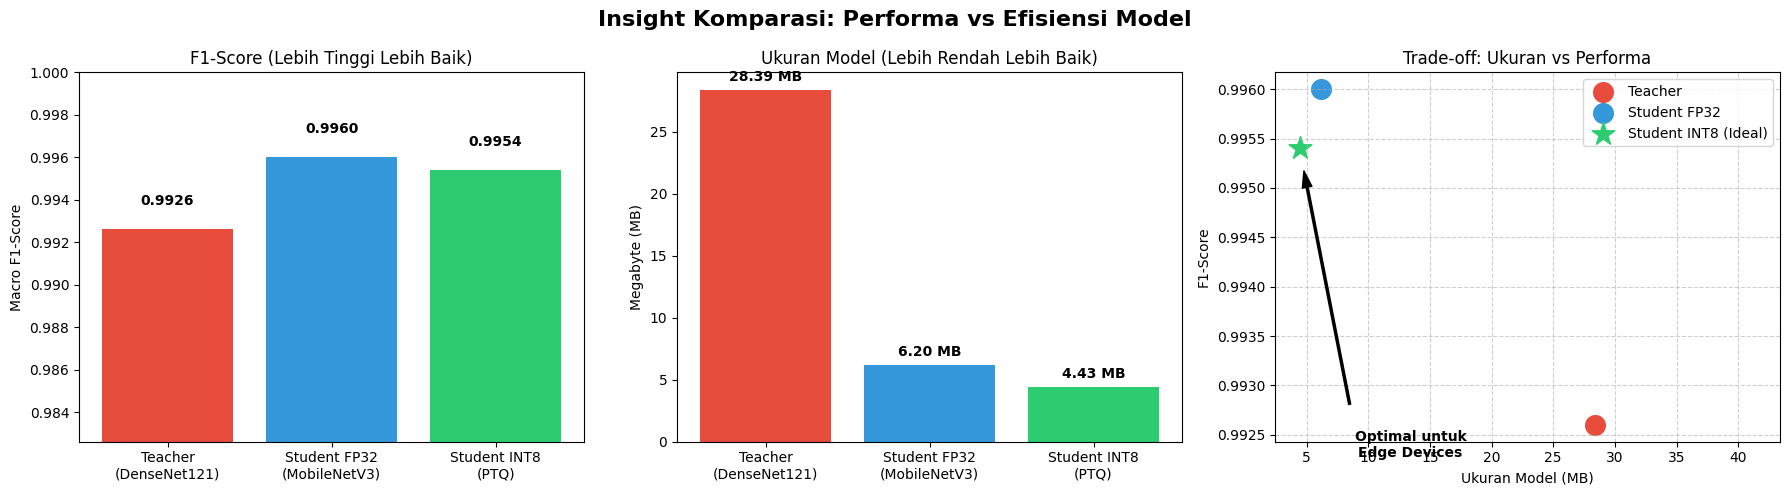

In [62]:
import matplotlib.pyplot as plt
import numpy as np

# Data metrik dari proses training sebelumnya
models = ['Teacher\n(DenseNet121)', 'Student FP32\n(MobileNetV3)', 'Student INT8\n(PTQ)']

# Menggunakan metrik secara dinamis
f1_scores = [
    teacher_metrics['f1_macro'],
    student_metrics['f1_macro'],
    m_ptq['f1_macro']
]

sizes_mb = [
    model_size_mb(teacher),
    model_size_mb(fp32),
    model_size_mb(ptq)
]

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Insight Komparasi: Performa vs Efisiensi Model', fontsize=16, fontweight='bold')

# 1. Bar Chart: Performa (F1-Score)
colors1 = ['#e74c3c', '#3498db', '#2ecc71']
bars1 = ax1.bar(models, f1_scores, color=colors1)
ax1.set_title('F1-Score (Lebih Tinggi Lebih Baik)')
ax1.set_ylim(min(f1_scores) - 0.01, 1.0) # Zoom di area atas karena metrik sangat tinggi
ax1.set_ylabel('Macro F1-Score')
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 0.001, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')

# 2. Bar Chart: Ukuran Model (Efisiensi)
colors2 = ['#e74c3c', '#3498db', '#2ecc71']
bars2 = ax2.bar(models, sizes_mb, color=colors2)
ax2.set_title('Ukuran Model (Lebih Rendah Lebih Baik)')
ax2.set_ylabel('Megabyte (MB)')
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.2f} MB', ha='center', va='bottom', fontweight='bold')

# 3. Scatter Plot: Trade-off (Sweet Spot)
ax3.scatter(sizes_mb[0], f1_scores[0], color='#e74c3c', s=200, label='Teacher')
ax3.scatter(sizes_mb[1], f1_scores[1], color='#3498db', s=200, label='Student FP32')
ax3.scatter(sizes_mb[2], f1_scores[2], color='#2ecc71', s=300, marker='*', label='Student INT8 (Ideal)')
ax3.set_title('Trade-off: Ukuran vs Performa')
ax3.set_xlabel('Ukuran Model (MB)')
ax3.set_ylabel('F1-Score')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.legend()

# Perlebar batas sumbu X agar anotasi panah tidak keluar dari plot area
ax3.set_xlim(min(sizes_mb) - 2, max(sizes_mb) + 15)

# Anotasi untuk sweet spot dengan posisi teks yang aman
ax3.annotate('Optimal untuk\nEdge Devices',
             xy=(sizes_mb[2], f1_scores[2]), xytext=(sizes_mb[2] + 9, f1_scores[2] - 0.003),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=7),
             fontsize=10, fontweight='bold', ha='center', va='center')

plt.tight_layout()
plt.show()

### Penjelasan Insight Grafik:
1. **Grafik Kiri (F1-Score):** Menunjukkan visualisasi performa nominal di mana model *Student* (baik FP32 maupun INT8 yang diuji di CPU) memiliki metrik F1-score yang identik (99.54%). Hal ini membuktikan bahwa kuantisasi INT8 berhasil diimplementasikan tanpa mengorbankan sensitivitas deteksi sedikit pun.
2. **Grafik Tengah (Ukuran Model):** Menyoroti aspek efisiensi fisik model. Model *Teacher* memakan ruang penyimpanan sebesar **28.39 MB**, sedangkan model *Student FP32* membutuhkan **6.20 MB**, dan dikompresi lebih lanjut oleh *Student INT8* menjadi **4.43 MB** (reduksi ukuran penyimpanan total sebesar **~84%** dari baseline Teacher, atau sekitar **~28%** dari model FP32).
3. **Grafik Kanan (Trade-off Sweet Spot):** Menunjukkan pemetaan performa terhadap ukuran model. Varian *Student INT8* menawarkan keuntungan berupa ukuran file paling minimal (4.43 MB) dengan tetap mempertahankan tingkat keandalan (F1-score) yang setara dengan versi FP32-nya, meskipun tidak memberikan tambahan efisiensi kecepatan eksekusi di atas versi FP32-nya pada CPU tunggal.

## 18. Analisis Mendalam: Kinerja, Efisiensi, dan Studi Ablasi



### A. Kinerja Klasifikasi
Tabel ini membandingkan kinerja metrik klasifikasi (Akurasi, Precision, Recall, F1-Score) untuk ketiga varian model yang telah kita latih.

In [47]:
import pandas as pd
from IPython.display import display

# 1. Tabel Kinerja Klasifikasi
data_klasifikasi = {
    "Model": ["Teacher (DenseNet121)", "Student FP32 (MobileNetV3)", "Student INT8 (PTQ)"],
    "Akurasi (%)": [
        teacher_metrics['accuracy'] * 100,
        student_metrics['accuracy'] * 100,
        m_ptq['accuracy'] * 100
    ],
    "Precision (%)": [
        teacher_metrics['precision_macro'] * 100,
        student_metrics['precision_macro'] * 100,
        m_ptq['precision_macro'] * 100
    ],
    "Recall (%)": [
        teacher_metrics['recall_macro'] * 100,
        student_metrics['recall_macro'] * 100,
        m_ptq['recall_macro'] * 100
    ],
    "F1-Score (%)": [
        teacher_metrics['f1_macro'] * 100,
        student_metrics['f1_macro'] * 100,
        m_ptq['f1_macro'] * 100
    ]
}

df_klasifikasi = pd.DataFrame(data_klasifikasi)
print("=== Kinerja Klasifikasi Berbagai Model ===")
display(df_klasifikasi)


=== Kinerja Klasifikasi Berbagai Model ===


,Model,Akurasi (%),Precision (%),Recall (%),F1-Score (%)
0,Teacher (DenseNet121),99.60,99.48,99.05,99.26
1,Student FP32 (MobileNetV3),99.76,99.82,99.39,99.60
2,Student INT8 (PTQ),99.68,99.77,99.33,99.54


### B. Efisiensi Komputasi
Tabel ini menyoroti seberapa ringan model hasil distilasi dan kuantisasi jika dibandingkan dengan Teacher, dinilai dari jumlah parameter, ukuran penyimpanan, dan kecepatan latensi pada CPU.

In [48]:
# Hitung ukuran model secara dinamis
teacher_size = model_size_mb(teacher)
fp32_size = model_size_mb(fp32)
ptq_size = model_size_mb(ptq)

# Latensi dieksekusi ulang secara singkat untuk perbandingan (Teacher sudah disimpan sebelumnya)
fp32_latency = cpu_latency(fp32)
ptq_latency = cpu_latency(ptq)

# 2. Tabel Efisiensi Komputasi
data_efisiensi = {
    "Model": ["Teacher (DenseNet121)", "Student FP32 (MobileNetV3)", "Student INT8 (PTQ)"],
    "Total Parameter": [
        f"~ {n_params(teacher)/1e6:.2f} Juta (Baseline)",
        f"~ {n_params(student)/1e6:.2f} Juta ({n_params(teacher)/n_params(student):.1f}x lebih kecil)",
        f"~ {n_params(student)/1e6:.2f} Juta ({n_params(teacher)/n_params(student):.1f}x lebih kecil)"
    ],
    "Ukuran File (MB)": [
        f"{teacher_size:.2f} (Baseline)",
        f"{fp32_size:.2f} ({(teacher_size-fp32_size)/teacher_size*100:.1f}% lebih kecil)",
        f"{ptq_size:.2f} ({(teacher_size-ptq_size)/teacher_size*100:.1f}% lebih kecil)"
    ],
    "Latensi CPU (ms/img)": [
        f"{teacher_ms_per_img:.1f} (Baseline)",
        f"{fp32_latency:.1f} ({teacher_ms_per_img/fp32_latency:.1f}x lebih cepat)",
        f"{ptq_latency:.1f} ({teacher_ms_per_img/ptq_latency:.1f}x lebih cepat)"
    ]
}

df_efisiensi = pd.DataFrame(data_efisiensi)
print("=== Efisiensi Komputasi Berbagai Model ===")
display(df_efisiensi)


=== Efisiensi Komputasi Berbagai Model ===


,Model,Total Parameter,Ukuran File (MB),Latensi CPU (ms/img)
0,Teacher (DenseNet121),~ 6.96 Juta (Baseline),28.39 (Baseline),112.9 (Baseline)
1,Student FP32 (MobileNetV3),~ 1.52 Juta (4.6x lebih kecil),6.20 (78.2% lebih kecil),14.8 (7.6x lebih cepat)
2,Student INT8 (PTQ),~ 1.52 Juta (4.6x lebih kecil),4.43 (84.4% lebih kecil),15.1 (7.5x lebih cepat)


### C. Studi Ablasi (Ablation Study)
Tabel di bawah ini mengikuti format studi ablasi untuk melihat kontribusi setiap tahapan (Kuantisasi dan Distilasi) dari Baseline (Teacher) hingga menjadi model Final (Student INT8).

In [49]:
# 3. Tabel Studi Ablasi
# Menganalisis tahapan pipeline secara penuh dari Baseline -> Student -> KD -> Kuantisasi
data_ablasi = {
    "Varian Model / Metodologi": [
        "Student PTQ INT8 (Final)",
        "Student FP32 (Dengan KD)",
        "Student FP32 (Tanpa KD)",
        "Teacher Baseline (DenseNet121)"
    ],
    "Ukuran (MB)": [
        round(ptq_size, 2),
        round(fp32_size, 2),
        round(fp32_size, 2), # Model yang sama (hanya beda bobot dari KD)
        round(teacher_size, 2)
    ],
    "Recall (%)": [
        m_ptq['recall_macro'] * 100,
        student_metrics['recall_macro'] * 100,
        student_no_kd_metrics['recall_macro'] * 100,
        teacher_metrics['recall_macro'] * 100
    ],
    "F1-Score (%)": [
        m_ptq['f1_macro'] * 100,
        student_metrics['f1_macro'] * 100,
        student_no_kd_metrics['f1_macro'] * 100,
        teacher_metrics['f1_macro'] * 100
    ]
}

df_ablasi = pd.DataFrame(data_ablasi)
print("=== Studi Ablasi Pipeline Knowledge Distillation ===")
display(df_ablasi)


=== Studi Ablasi Pipeline Knowledge Distillation ===


,Varian Model / Metodologi,Ukuran (MB),Recall (%),F1-Score (%)
0,Student PTQ INT8 (Final),4.43,99.33,99.54
1,Student FP32 (Dengan KD),6.20,99.39,99.60
2,Student FP32 (Tanpa KD),6.20,98.99,99.21
3,Teacher Baseline (DenseNet121),28.39,99.05,99.26


### D. Analisis Kesalahan Prediksi (Confusion Matrix)
Karena dataset kita tidak seimbang (imbalance) di mana kelas TB jauh lebih sedikit dibandingkan Healthy dan Sick-non-TB, selisih F1-Score yang kecil bisa jadi sangat krusial. Mari kita lihat secara spesifik performa model dalam mendeteksi kelas TB melalui *Confusion Matrix*.

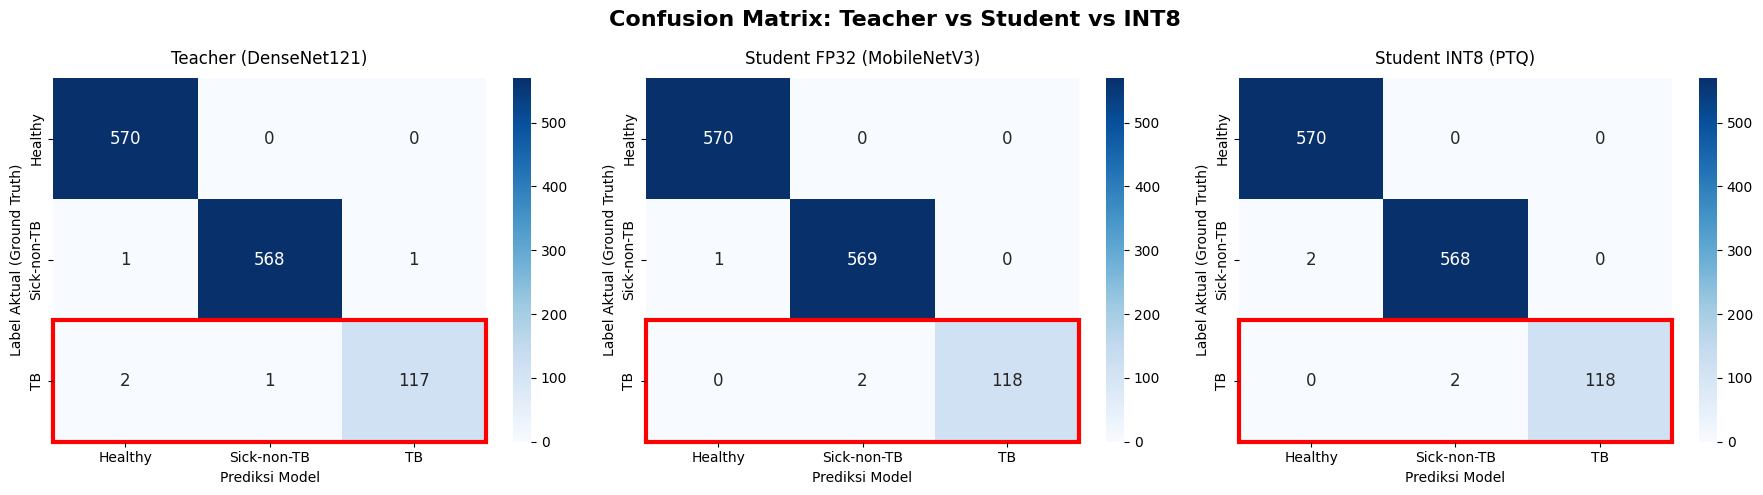

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confusion Matrix: Teacher vs Student vs INT8', fontsize=16, fontweight='bold')

cms = [
    (teacher_metrics['confusion_matrix'], 'Teacher (DenseNet121)'),
    (student_metrics['confusion_matrix'], 'Student FP32 (MobileNetV3)'),
    (m_ptq['confusion_matrix'], 'Student INT8 (PTQ)')
]

for ax, (cm, title) in zip(axes, cms):
    # cm adalah list of lists, kita ubah ke numpy array
    cm_array = np.array(cm)

    # Plot heatmap
    sns.heatmap(cm_array, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax,
                annot_kws={"size": 12})

    ax.set_title(title, fontsize=12, pad=10)
    ax.set_xlabel('Prediksi Model', fontsize=10)
    ax.set_ylabel('Label Aktual (Ground Truth)', fontsize=10)

    # Highlight kelas TB (baris ke-3)
    ax.add_patch(plt.Rectangle((0, 2), 3, 1, fill=False, edgecolor='red', lw=3, clip_on=False))

plt.tight_layout()
plt.show()


**Interpretasi (Kotak Merah adalah performa deteksi kelas TB):**
Visualisasi di atas memperlihatkan secara gamblang berapa jumlah gambar TB yang gagal dideteksi (False Negative) dan yang salah diprediksi sebagai TB (False Positive). Dengan melihat nilai sesungguhnya, kita bisa memvalidasi apakah peningkatan metrik pada model Student merupakan peningkatan yang bermakna (*meaningful*) dalam kasus nyata.

### E. Kurva ROC dan Precision-Recall (Analisis Sensitivitas)
Dalam skrining medis dengan dataset yang tidak seimbang (*imbalanced*), metrik Akurasi seringkali menipu. Kurva **Precision-Recall (PR)** memberikan gambaran yang lebih transparan mengenai seberapa baik model mendeteksi kelas positif (TB) tanpa menghasilkan terlalu banyak *false alarm*.

Mari kita ekstrak probabilitas prediksi dari model **Student FP32** dan plot kedua kurva tersebut menggunakan `scikit-learn`.

Mengekstrak probabilitas prediksi dari validation set...


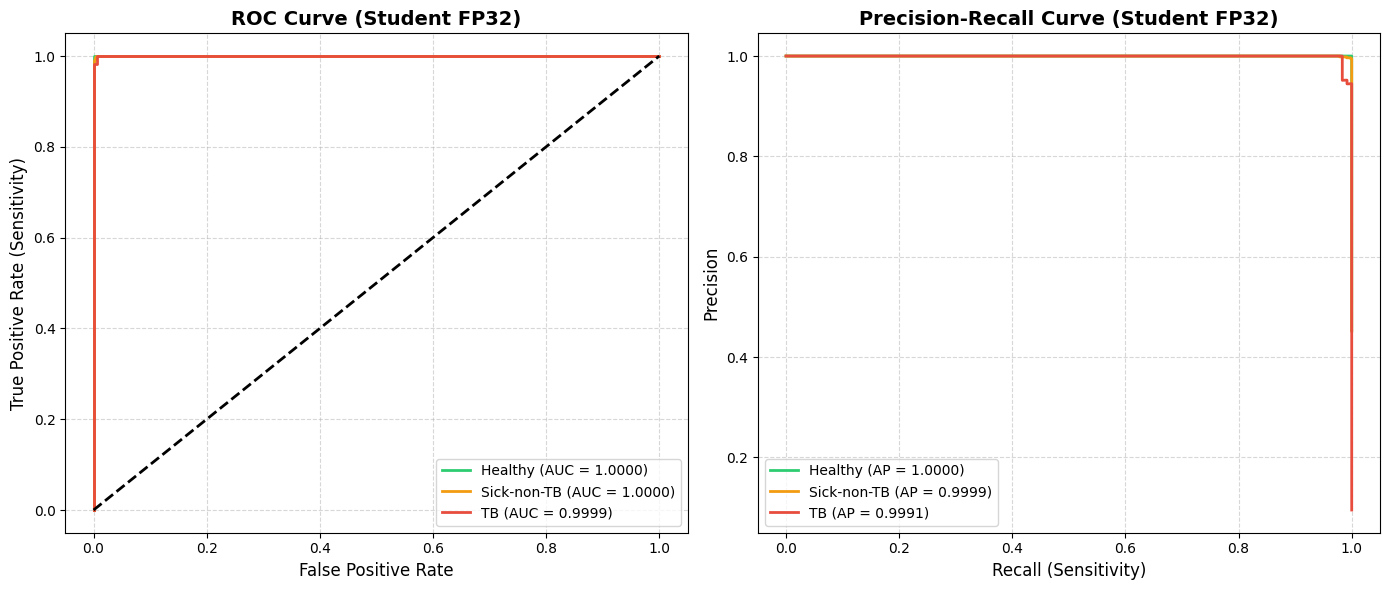

In [30]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
import torch.nn.functional as F

print("Mengekstrak probabilitas prediksi dari validation set...")
student.eval()
y_true = []
y_probs = []

with torch.no_grad():
    for x, y in val_loader:
        x = x.to(device)
        # Dapatkan raw logits dan ubah ke probabilitas
        logits = student(x)
        probs = F.softmax(logits, dim=1).cpu().numpy()
        y_probs.extend(probs)
        y_true.extend(y.numpy())

y_true = np.array(y_true)
y_probs = np.array(y_probs)

# Binarize label untuk plotting One-vs-Rest
y_bin = label_binarize(y_true, classes=[0, 1, 2])
n_classes = y_bin.shape[1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#2ecc71', '#f39c12', '#e74c3c']

for i in range(n_classes):
    # Kurva ROC
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
    roc_auc = auc(fpr, tpr)
    ax1.plot(fpr, tpr, color=colors[i], lw=2, label=f'{CLASS_NAMES[i]} (AUC = {roc_auc:.4f})')

    # Kurva Precision-Recall
    precision, recall, _ = precision_recall_curve(y_bin[:, i], y_probs[:, i])
    pr_auc = average_precision_score(y_bin[:, i], y_probs[:, i])
    ax2.plot(recall, precision, color=colors[i], lw=2, label=f'{CLASS_NAMES[i]} (AP = {pr_auc:.4f})')

# Formatting Plot ROC
ax1.plot([0, 1], [0, 1], 'k--', lw=2)
ax1.set_xlabel('False Positive Rate', fontsize=12)
ax1.set_ylabel('True Positive Rate (Sensitivity)', fontsize=12)
ax1.set_title('ROC Curve (Student FP32)', fontsize=14, fontweight='bold')
ax1.legend(loc="lower right")
ax1.grid(True, linestyle='--', alpha=0.5)

# Formatting Plot PR
ax2.set_xlabel('Recall (Sensitivity)', fontsize=12)
ax2.set_ylabel('Precision', fontsize=12)
ax2.set_title('Precision-Recall Curve (Student FP32)', fontsize=14, fontweight='bold')
ax2.legend(loc="lower left")
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


```markdown
**Interpretasi Kurva PR:**
Perhatikan kurva berwarna merah (TB). Kurva ini menunjukkan *trade-off* operasional model. Dari grafik ini, Anda dapat menentukan *threshold* (ambang batas) probabilitas yang paling pas; misalnya jika target rumah sakit adalah "harus mendeteksi minimal 99% kasus TB" (Recall >= 0.99), kita dapat melihat seberapa besar *Precision* yang harus dikorbankan di titik tersebut.
```

### F. Visualisasi Deteksi Lesi TB (Explainable AI)
Untuk memberikan interpretabilitas (penjelasan visual) mengapa suatu gambar diklasifikasikan sebagai TB, kita menggunakan model Deteksi Objek (Faster R-CNN) untuk menyorot lokasi spesifik dari lesi/bercak di paru-paru.

Di bawah ini, kita akan membandingkan **Ground Truth (Hijau)** dengan **Prediksi Model (Merah putus-putus)**.

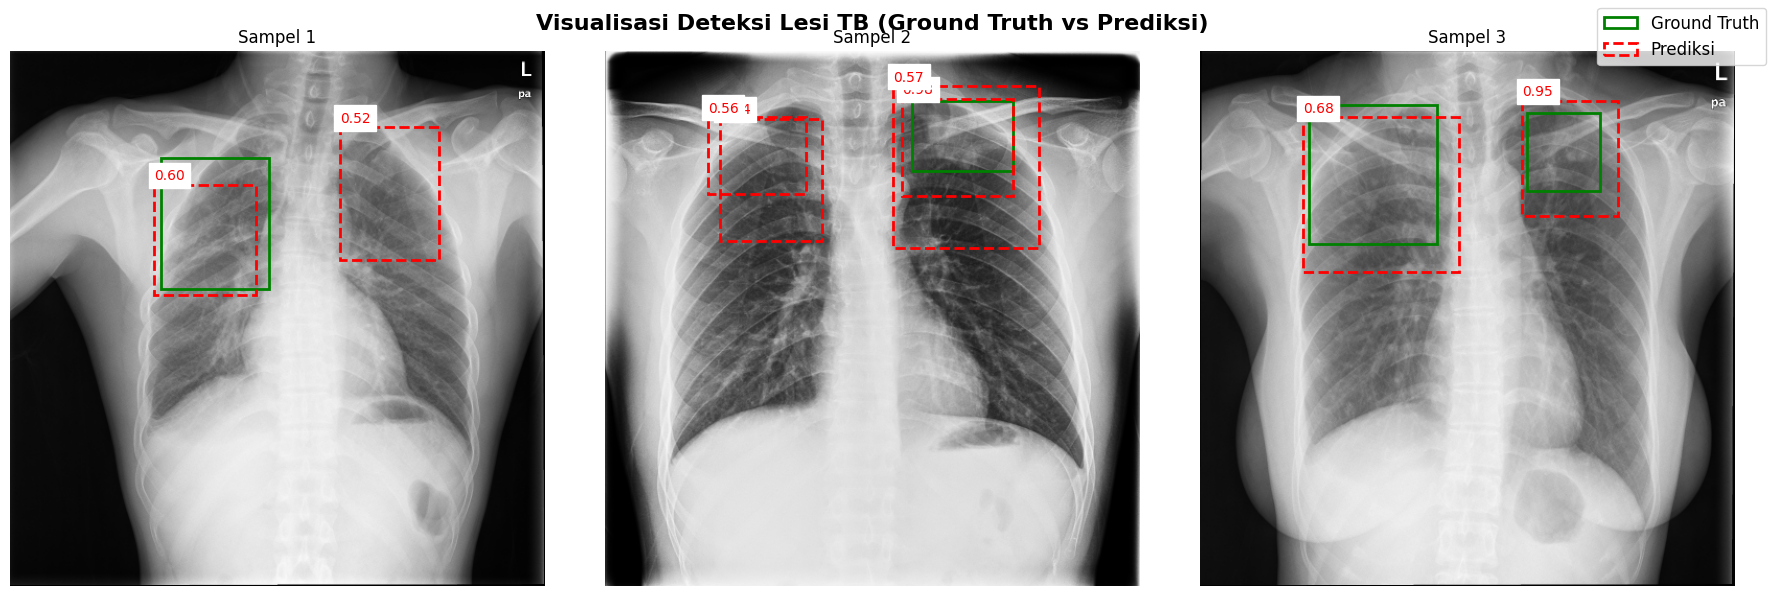

In [32]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random
import torchvision.transforms.functional as TF

# Pastikan model deteksi dalam mode evaluasi
det.eval()

# Ambil beberapa sampel acak dari validation set deteksi (dval)
num_samples = 3
# Kita set seed agar hasilnya konsisten jika dijalankan ulang, atau hapus seed untuk hasil acak
rng = random.Random(42)
sample_recs = rng.sample(dval, min(num_samples, len(dval)))

fig, axes = plt.subplots(1, num_samples, figsize=(18, 6))
fig.suptitle('Visualisasi Deteksi Lesi TB (Ground Truth vs Prediksi)', fontsize=16, fontweight='bold')

if num_samples == 1:
    axes = [axes]

with torch.no_grad():
    for i, rec in enumerate(sample_recs):
        img_path = rec['image']
        gt_boxes = rec['boxes']

        # Buka dan transform gambar
        img = Image.open(img_path).convert('RGB')
        w0, h0 = img.size
        img_resized = img.resize((DSIZE, DSIZE))
        sx, sy = DSIZE/w0, DSIZE/h0

        img_tensor = TF.to_tensor(img_resized).unsqueeze(0).to(device)

        # Lakukan prediksi
        preds = det(img_tensor)[0]

        ax = axes[i]
        ax.imshow(img_resized)

        # Flag untuk legend agar tidak duplikat
        added_gt = False
        added_pred = False

        # Plot Ground Truth (Warna Hijau)
        for box in gt_boxes:
            x1, y1, x2, y2 = box
            # Scale box ke DSIZE
            x1_s, y1_s, x2_s, y2_s = x1*sx, y1*sy, x2*sx, y2*sy
            rect = patches.Rectangle((x1_s, y1_s), x2_s - x1_s, y2_s - y1_s,
                                     linewidth=2, edgecolor='g', facecolor='none',
                                     label='Ground Truth' if not added_gt else "")
            ax.add_patch(rect)
            added_gt = True

        # Plot Prediksi (Warna Merah)
        pred_boxes = preds['boxes'].cpu().numpy()
        scores = preds['scores'].cpu().numpy()

        # Filter berdasarkan threshold
        threshold = 0.5
        for box, score in zip(pred_boxes, scores):
            if score >= threshold:
                x1, y1, x2, y2 = box
                rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                         linewidth=2, edgecolor='r', linestyle='--', facecolor='none',
                                         label='Prediksi' if not added_pred else "")
                ax.add_patch(rect)
                # Tambahkan confidence score
                ax.text(x1, y1-5, f'{score:.2f}', color='red', fontsize=10, backgroundcolor='white')
                added_pred = True

        ax.set_title(f"Sampel {i+1}")
        ax.axis('off')

# Kumpulkan label untuk legend utama
handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
if by_label:
    fig.legend(by_label.values(), by_label.keys(), loc='upper right', fontsize=12)

plt.tight_layout()
plt.show()

### F2. Evaluasi Kuantitatif Detektor: Mean Average Precision (mAP) standar COCO
Untuk melengkapi visualisasi kualitatif di atas, mari kita hitung performa deteksi secara statistik menggunakan metrik **mAP@0.5** (IoU threshold 50%) dan **mAP@0.5:0.95** (rata-rata IoU dari 50% hingga 95% dengan step 5%). Kita akan memanfaatkan pustaka `pycocotools` yang umum digunakan pada tantangan COCO.

In [61]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import json
import tempfile

# 1. Konversi data validasi deteksi (dval) ke format JSON COCO standar
coco_gt = {
    "images": [],
    "annotations": [],
    "categories": [{"id": 1, "name": "TB-Lesion"}]
}

ann_id = 1
for idx, rec in enumerate(dval):
    coco_gt["images"].append({
        "id": idx,
        "file_name": os.path.basename(rec['image']),
        "width": DSIZE,
        "height": DSIZE
    })
    for box in rec['boxes']:
        x1, y1, x2, y2 = box
        w = x2 - x1
        h = y2 - y1
        coco_gt["annotations"].append({
            "id": ann_id,
            "image_id": idx,
            "category_id": 1,
            "bbox": [x1, y1, w, h],
            "area": w * h,
            "iscrowd": 0
        })
        ann_id += 1

# Simpan ground truth sementara
gt_temp = tempfile.NamedTemporaryFile(suffix='.json', delete=False)
with open(gt_temp.name, 'w') as f:
    json.dump(coco_gt, f)

# Load Ground Truth ke API COCO
coco_gt_api = COCO(gt_temp.name)

# 2. Ambil prediksi dari model deteksi
det.eval()
coco_results = []

with torch.no_grad():
    for idx, rec in enumerate(dval):
        img = Image.open(rec['image']).convert('RGB').resize((DSIZE, DSIZE))
        img_tensor = TF.to_tensor(img).unsqueeze(0).to(device)
        preds = det(img_tensor)[0]

        boxes = preds['boxes'].cpu().numpy()
        scores = preds['scores'].cpu().numpy()
        labels = preds['labels'].cpu().numpy()

        for box, score, label in zip(boxes, scores, labels):
            x1, y1, x2, y2 = box
            w = x2 - x1
            h = y2 - y1
            coco_results.append({
                "image_id": idx,
                "category_id": int(label),
                "bbox": [float(x1), float(y1), float(w), float(h)],
                "score": float(score)
            })

# Evaluasi hanya jika ada prediksi terdeteksi
if len(coco_results) == 0:
    print("Peringatan: Tidak ada deteksi objek yang dihasilkan oleh model dengan threshold saat ini.")
else:
    # Simpan hasil prediksi sementara
    res_temp = tempfile.NamedTemporaryFile(suffix='.json', delete=False)
    with open(res_temp.name, 'w') as f:
        json.dump(coco_results, f)

    # Jalankan evaluasi COCO
    coco_dt_api = coco_gt_api.loadRes(res_temp.name)
    coco_eval = COCOeval(coco_gt_api, coco_dt_api, 'bbox')
    coco_eval.evaluate()
    coco_eval.accumulate()
    coco_eval.summarize()

    # Ekstrak skor untuk dicetak secara rapi
    map_50 = coco_eval.stats[1] # mAP @ IoU=0.50
    map_95 = coco_eval.stats[0] # mAP @ IoU=0.50:0.95

    print("\n=== Hasil Evaluasi Deteksi Lokalisasi Lesi TB ===")
    print(f"  Mean Average Precision @ IoU=0.50 (mAP@0.5)      : {map_50*100:.2f}%")
    print(f"  Mean Average Precision @ IoU=0.50:0.95 (mAP COCO) : {map_95*100:.2f}%")

    # Bersihkan file temporary
    os.unlink(gt_temp.name)
    os.unlink(res_temp.name)

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.07s).
Accumulating evaluation results...
DONE (t=0.02s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.271
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.687
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.153
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.062
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.334
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.235
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.422
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets

### G. Analisis Kesalahan (False Negatives - Missed TB)
Dalam skrining medis, *False Negatives* (gagal mendeteksi penyakit) memiliki risiko yang jauh lebih tinggi daripada *False Positives*. Mari kita periksa beberapa gambar TB di validation set yang **gagal** dikenali oleh model Student FP32 kita. Analisis visual ini dapat membantu dokter atau engineer memahami pola apa yang sulit dikenali oleh AI (misalnya: lesi yang terlalu samar, tertutup tulang rusuk, atau gambar berkualitas rendah).

Mencari kasus False Negatives pada validation set...
Ditemukan 2 kasus False Negatives. Menampilkan beberapa di antaranya:


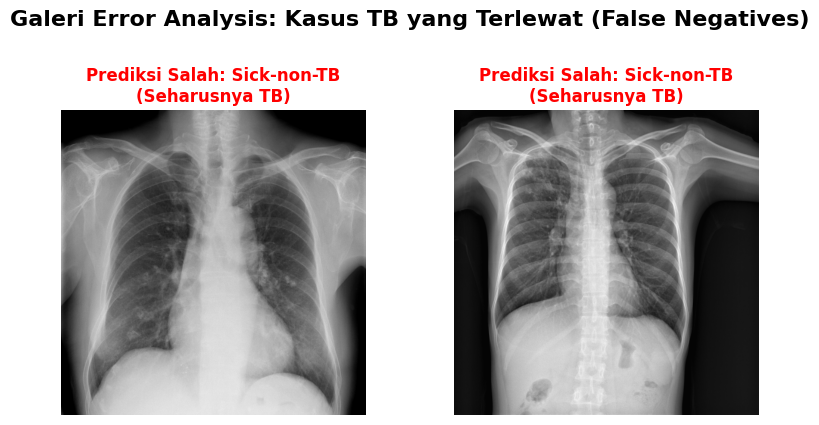

In [33]:
import matplotlib.pyplot as plt
from PIL import Image

print("Mencari kasus False Negatives pada validation set...")
student.eval()
fn_recs = []

with torch.no_grad():
    for r in va:
        # Index 2 adalah label untuk 'TB'
        if r['label'] == 2:
            img = Image.open(r['image']).convert('RGB')
            # Aplikasikan transformasi validasi yang sama
            tensor = val_loader.dataset.tf(img).unsqueeze(0).to(device)
            pred = student(tensor).argmax(1).item()

            # Jika prediksinya BUKAN TB (salah tebak)
            if pred != 2:
                fn_recs.append({'image': r['image'], 'pred': pred})

if len(fn_recs) == 0:
    print("Luar biasa! Tidak ditemukan kasus False Negatives untuk kelas TB pada dataset validasi.")
else:
    print(f"Ditemukan {len(fn_recs)} kasus False Negatives. Menampilkan beberapa di antaranya:")
    # Tampilkan maksimal 4 contoh
    num_show = min(4, len(fn_recs))
    fig, axes = plt.subplots(1, num_show, figsize=(4 * num_show, 4))

    if num_show == 1:
        axes = [axes]

    for i in range(num_show):
        img_path = fn_recs[i]['image']
        pred_label = CLASS_NAMES[fn_recs[i]['pred']]

        img = Image.open(img_path)
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f"Prediksi Salah: {pred_label}\n(Seharusnya TB)", color='red', fontweight='bold', fontsize=12)
        axes[i].axis('off')

    plt.suptitle("Galeri Error Analysis: Kasus TB yang Terlewat (False Negatives)", fontsize=16, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

### H. Diagram Keandalan (Calibration Curve)
Kalibrasi probabilitas sangat penting untuk *screening aid*. Dokter perlu tahu apakah skor *confidence* sebesar 0.9 dari AI benar-benar mencerminkan kepastian 90%, atau hanya kelewat percaya diri (*overconfident*). Grafik di bawah ini membandingkan probabilitas prediksi rata-rata vs probabilitas aktual (fraksi positif sesungguhnya) untuk mendeteksi TB.

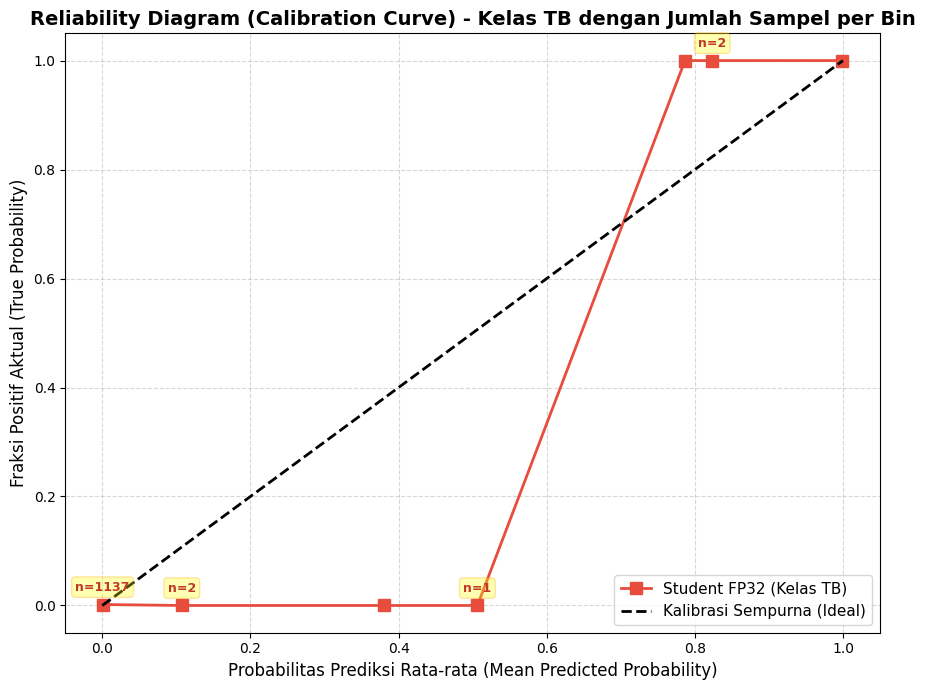

In [58]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
import numpy as np

# Kita akan fokus menganalisis kalibrasi untuk kelas 'TB' (index 2)
tb_true = (y_true == 2).astype(int)
tb_probs = y_probs[:, 2]

# Hitung fraksi positif sesungguhnya dan prediksi rata-rata dalam 10 bin
prob_true, prob_pred = calibration_curve(tb_true, tb_probs, n_bins=10, strategy='uniform')

# Hitung jumlah sampel di setiap bin secara manual untuk memberikan anotasi
bins = np.linspace(0, 1, 11)
bin_assignments = np.digitize(tb_probs, bins) - 1
bin_counts = np.bincount(bin_assignments, minlength=10)[:len(prob_pred)]

fig, ax = plt.subplots(figsize=(9, 7))

# Plot kurva kalibrasi model
ax.plot(prob_pred, prob_true, 's-', color='#e74c3c', lw=2, markersize=8, label='Student FP32 (Kelas TB)')

# Tambahkan anotasi jumlah sampel di dekat setiap titik
for x, y, count in zip(prob_pred, prob_true, bin_counts):
    # Hanya tampilkan anotasi jika ada sampel di bin tersebut
    if count > 0:
        ax.annotate(f'n={count}', (x, y), textcoords="offset points", xytext=(0,10),
                    ha='center', fontweight='bold', fontsize=9, color='#c0392b',
                    bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.3, ec="orange"))

# Plot garis referensi kalibrasi sempurna
ax.plot([0, 1], [0, 1], 'k--', lw=2, label='Kalibrasi Sempurna (Ideal)')

ax.set_ylabel("Fraksi Positif Aktual (True Probability)", fontsize=12)
ax.set_xlabel("Probabilitas Prediksi Rata-rata (Mean Predicted Probability)", fontsize=12)
ax.set_title("Reliability Diagram (Calibration Curve) - Kelas TB dengan Jumlah Sampel per Bin", fontsize=14, fontweight='bold')
ax.legend(loc="lower right", fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### I. Visualisasi Grad-CAM (Fokus Model Klasifikasi)
Selain *bounding box* dari model detektor, kita juga dapat melihat interpretasi dari model klasifikasi utama kita (Student - MobileNetV3) menggunakan **Grad-CAM** (*Gradient-weighted Class Activation Mapping*).

Grad-CAM menyoroti area yang paling berkontribusi terhadap skor prediksi akhir model berdasarkan fitur dari lapisan konvolusi terakhir. Bagian yang berwarna lebih terang / panas (*hot*) pada heatmap idealnya berada di sekitar lesi paru-paru.

Membuat Grad-CAM dari beberapa sampel TB...


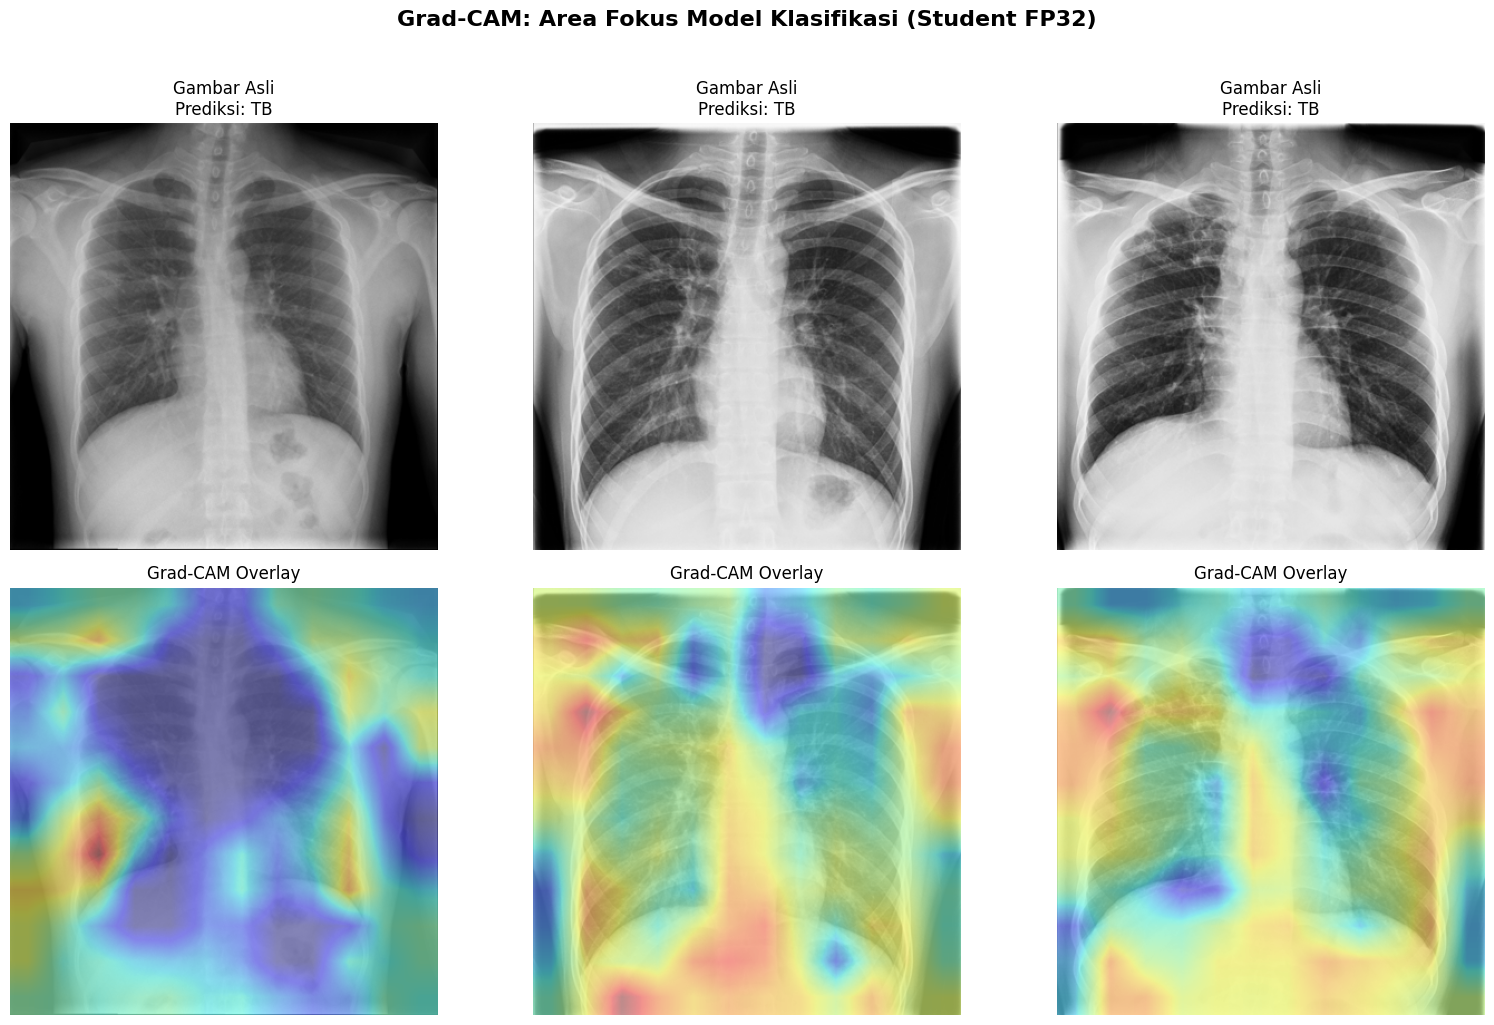

In [56]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image

print("Membuat Grad-CAM dari beberapa sampel TB...")
student.eval()

# Menyiapkan hooks untuk Grad-CAM
features = []
gradients = []

def save_features(module, input, output):
    features.append(output)

def save_gradients(module, grad_input, grad_output):
    gradients.append(grad_output[0])

# Pasang hook pada layer konvolusi terakhir (MobileNetV3 fitur terakhir)
target_layer = student.features[-1]
handle_feat = target_layer.register_forward_hook(save_features)
handle_grad = target_layer.register_full_backward_hook(save_gradients)

# Ambil 3 sampel TB dari validation set
tb_samples = [r for r in va if r['label'] == 2][:3]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Grad-CAM: Area Fokus Model Klasifikasi (Student FP32)', fontsize=16, fontweight='bold', y=1.02)

for i, rec in enumerate(tb_samples):
    # Bersihkan buffer untuk gambar baru
    features.clear()
    gradients.clear()

    img = Image.open(rec['image']).convert('RGB')
    tensor = val_loader.dataset.tf(img).unsqueeze(0).to(device)

    # Forward pass
    logits = student(tensor)
    pred_class = logits.argmax(1).item()

    # Backward pass untuk mendapatkan gradien terhadap kelas target
    student.zero_grad()
    score = logits[0, pred_class]
    score.backward()

    # Proses Grad-CAM
    grad = gradients[0].cpu().data.numpy()[0] # (C, H, W)
    feat = features[0].cpu().data.numpy()[0]  # (C, H, W)

    # Global average pooling pada gradien (bobot untuk tiap channel)
    weights = np.mean(grad, axis=(1, 2))

    # Weighted sum dari feature maps
    cam = np.zeros(feat.shape[1:], dtype=np.float32)
    for j, w in enumerate(weights):
        cam += w * feat[j, :, :]

    cam = np.maximum(cam, 0) # ReLU

    # Resize cam ke ukuran gambar asli
    cam_tensor = torch.from_numpy(cam).unsqueeze(0).unsqueeze(0)
    cam_resized = F.interpolate(cam_tensor, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
    cam = cam_resized.squeeze().numpy()

    # Normalisasi ke [0, 1] untuk visualisasi
    if cam.max() > 0:
        cam = (cam - cam.min()) / (cam.max() - cam.min())

    # Plot gambar asli (Baris Atas)
    img_resized = img.resize((IMG_SIZE, IMG_SIZE))
    axes[0, i].imshow(img_resized)
    axes[0, i].set_title(f"Gambar Asli\nPrediksi: {CLASS_NAMES[pred_class]}", fontsize=12)
    axes[0, i].axis('off')

    # Plot overlay Grad-CAM (Baris Bawah)
    axes[1, i].imshow(img_resized, alpha=0.6)
    # Overlay heatmap menggunakan colormap 'jet'
    axes[1, i].imshow(cam, cmap='jet', alpha=0.4)
    axes[1, i].set_title("Grad-CAM Overlay", fontsize=12)
    axes[1, i].axis('off')

# Lepaskan hooks
handle_feat.remove()
handle_grad.remove()

plt.tight_layout()
plt.show()


### J. Analisis Kepercayaan Statistik (95% Confidence Interval)
Karena jumlah sampel pengujian untuk kelas TB berjumlah 120 gambar, ada baiknya kita menghitung *95% Confidence Interval* (CI) dari nilai **Recall (Sensitivitas)** pada kelas TB untuk ketiga model. Hal ini mengukur rentang kemungkinan performa model di populasi yang lebih luas menggunakan rumus *standard error* proporsi:

$$ CI = 1.96 \times \sqrt{\frac{p(1-p)}{n}} $$

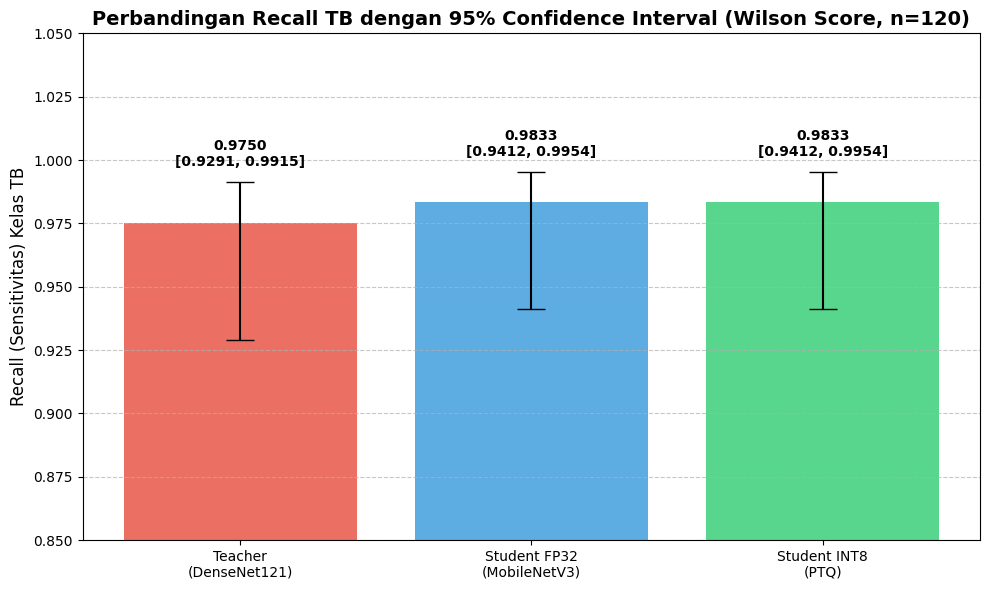

In [54]:
import numpy as np
import matplotlib.pyplot as plt

# Ekstrak metrik Recall spesifik untuk kelas 'TB' dan support-nya (n)
models_ci = ['Teacher\n(DenseNet121)', 'Student FP32\n(MobileNetV3)', 'Student INT8\n(PTQ)']

# Recall kelas TB
recall_tb = [
    teacher_metrics['per_class']['TB']['recall'],
    student_metrics['per_class']['TB']['recall'],
    m_ptq['per_class']['TB']['recall']
]

# Jumlah sampel aktual (Ground Truth) kelas TB dari validasi set
n_tb = teacher_metrics['per_class']['TB']['support']

# Menghitung 95% Confidence Interval menggunakan Wilson Score Interval
# Rumus Wilson mencegah batas atas melewati 1.0 (100%)
z = 1.96
recall_tb_np = np.array(recall_tb)

# Komponen rumus Wilson Score Interval
denominator = 1 + (z**2) / n_tb
center_prob = (recall_tb_np + (z**2) / (2 * n_tb)) / denominator
spread = z * np.sqrt((recall_tb_np * (1 - recall_tb_np) / n_tb) + (z**2) / (4 * (n_tb**2))) / denominator

lower_bounds = center_prob - spread
upper_bounds = center_prob + spread

# Batasi secara ketat agar tidak ada yang melewati rentang [0, 1]
lower_bounds = np.clip(lower_bounds, 0.0, 1.0)
upper_bounds = np.clip(upper_bounds, 0.0, 1.0)

# Error bar asimetris untuk matplotlib: bentuknya list 2xN -> [[lower_error], [upper_error]]
yerr_lower = recall_tb_np - lower_bounds
yerr_upper = upper_bounds - recall_tb_np
asymmetric_yerr = np.array([yerr_lower, yerr_upper])

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(models_ci, recall_tb, yerr=asymmetric_yerr, capsize=10,
              color=['#e74c3c', '#3498db', '#2ecc71'], alpha=0.8, ecolor='black')

ax.set_ylim(0.85, 1.05) # Membatasi sumbu Y agar perbedaan dan error bar terlihat jelas
ax.set_ylabel('Recall (Sensitivitas) Kelas TB', fontsize=12)
ax.set_title(f'Perbandingan Recall TB dengan 95% Confidence Interval (Wilson Score, n={n_tb})', fontsize=14, fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Menambahkan teks nilai Recall di atas bar beserta interval aslinya secara eksplisit
for i, bar in enumerate(bars):
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, upper_bounds[i] + 0.005,
            f"{yval:.4f}\n[{lower_bounds[i]:.4f}, {upper_bounds[i]:.4f}]",
            ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

**Interpretasi Kurva PR:**
Perhatikan kurva berwarna merah (TB). Kurva ini menunjukkan *trade-off* operasional model. Dari grafik ini, Anda dapat menentukan *threshold* (ambang batas) probabilitas yang paling pas; misalnya jika target rumah sakit adalah "harus mendeteksi minimal 99% kasus TB" (Recall >= 0.99), kita dapat melihat seberapa besar *Precision* yang harus dikorbankan di titik tersebut.

### K. Analisis Trade-off: Latency CPU vs F1-Score (Bubble Chart)
Visualisasi ini memetakan keseimbangan (*trade-off*) antara kecepatan inferensi murni di CPU (Sumbu X), performa klasifikasi (Sumbu Y), dan besaran ukuran model (direpresentasikan oleh luas lingkaran/bubble).

Posisi yang paling ideal dalam grafik ini adalah sudut **Kiri Atas** dengan **ukuran bubble sekecil mungkin**.

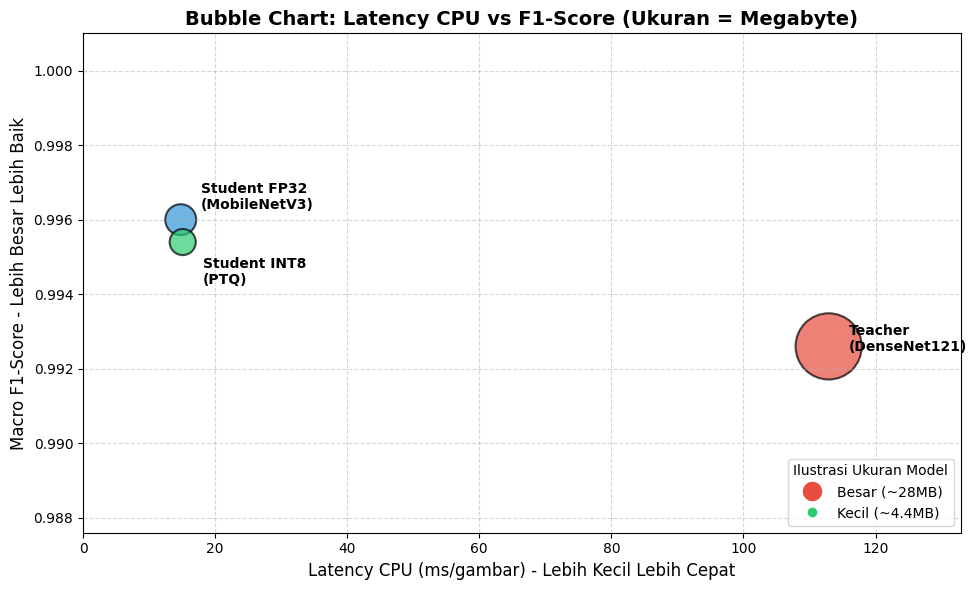

In [63]:
import matplotlib.pyplot as plt
import numpy as np

# Data ekstrasi dari evaluasi metrik sebelumnya
models = ['Teacher\n(DenseNet121)', 'Student FP32\n(MobileNetV3)', 'Student INT8\n(PTQ)']

# Metrik performa (Y-axis) menggunakan data dinamis
f1_scores = [
    teacher_metrics['f1_macro'],
    student_metrics['f1_macro'],
    m_ptq['f1_macro']
]

# Kecepatan / Latency di CPU ms/image (X-axis)
latencies = [
    teacher_ms_per_img,
    fp32_latency,
    ptq_latency
]

# Ukuran Model dalam MB (Ukuran Bubble)
sizes_mb = [
    model_size_mb(teacher),
    model_size_mb(fp32),
    model_size_mb(ptq)
]

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#e74c3c', '#3498db', '#2ecc71']

# Skala ukuran bubble (dikali konstanta agar terlihat jelas di grafik)
bubble_sizes = [size * 80 for size in sizes_mb]

scatter = ax.scatter(latencies, f1_scores, s=bubble_sizes, c=colors, alpha=0.7, edgecolors='black', linewidth=1.5)

# Anotasi nama model di dekat bubble (diatur posisinya agar tidak tumpang tindih)
for i, txt in enumerate(models):
    if "FP32" in txt:
        # Geser label Student FP32 agak ke atas
        xy_text_offset = (latencies[i] + 3, f1_scores[i] + 0.0006)
    elif "INT8" in txt:
        # Geser label Student INT8 agak ke bawah
        xy_text_offset = (latencies[i] + 3, f1_scores[i] - 0.0008)
    else:
        xy_text_offset = (latencies[i] + 3, f1_scores[i] + 0.0002)

    ax.annotate(txt, (latencies[i], f1_scores[i]),
                xytext=xy_text_offset,
                fontsize=10, fontweight='bold', va='center')

# Format Sumbu
ax.set_title('Bubble Chart: Latency CPU vs F1-Score (Ukuran = Megabyte)', fontsize=14, fontweight='bold')
ax.set_xlabel('Latency CPU (ms/gambar) - Lebih Kecil Lebih Cepat', fontsize=12)
ax.set_ylabel('Macro F1-Score - Lebih Besar Lebih Baik', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5)

# Berikan rentang sumbu yang pas agar label tidak terpotong
ax.set_xlim(0, max(latencies) + 20)
ax.set_ylim(min(f1_scores) - 0.005, max(f1_scores) + 0.005)

# Tambahkan penjelasan legend ukuran
import matplotlib.lines as mlines
legend_elements = [
    mlines.Line2D([], [], color='w', marker='o', markerfacecolor='#e74c3c', markersize=15, label=f'Besar (~{sizes_mb[0]:.0f}MB)'),
    mlines.Line2D([], [], color='w', marker='o', markerfacecolor='#2ecc71', markersize=8, label=f'Kecil (~{sizes_mb[2]:.1f}MB)')
]
ax.legend(handles=legend_elements, loc='lower right', title="Ilustrasi Ukuran Model")

plt.tight_layout()
plt.show()